# RAPID impact-classifier investigation

This notebook trains and inspects the discrete impact classifier. Labels are derived from the RAPID response only for training; geometry/resistance features are the model inputs.

In [3]:
from pathlib import Path
from datetime import datetime, timezone
import subprocess
import sys
import pandas as pd
import matplotlib.pyplot as plt

REPO_ROOT = Path.cwd().resolve()
if not (REPO_ROOT / 'RAPID').exists():
    REPO_ROOT = REPO_ROOT.parents[1]
OUTPUT_ROOT = Path('/Volumes/PhD/river_hierarchy/network_variants/output')
EXAMPLE_IDS = ['02', '03', '05', '11', '21']  # edit when more real-network outputs are available
RUN_DIR = REPO_ROOT / 'RAPID' / 'classification' / 'results' / f"classifier-notebook-{datetime.now(timezone.utc):%Y%m%dT%H%M%SZ}"


In [4]:
command = [sys.executable, str(REPO_ROOT / 'RAPID/classification/train_rapid_impact_classifier.py'),
           '--output-root', str(OUTPUT_ROOT), '--results-dir', str(RUN_DIR),
           '--example-ids', *EXAMPLE_IDS]
subprocess.run(command, cwd=REPO_ROOT, check=True)


Wrote /Users/6256481/Code/river-hierarchy/RAPID/classification/results/classifier-notebook-20260824T124656Z
Recommended model: shallow_tree


CompletedProcess(args=['/opt/anaconda3/envs/UNC/bin/python', '/Users/6256481/Code/river-hierarchy/RAPID/classification/train_rapid_impact_classifier.py', '--output-root', '/Volumes/PhD/river_hierarchy/network_variants/output', '--results-dir', '/Users/6256481/Code/river-hierarchy/RAPID/classification/results/classifier-notebook-20260824T124656Z', '--example-ids', '02', '03', '05', '11', '21'], returncode=0)

In [5]:
scores = pd.read_csv(RUN_DIR / 'grouped_cv_scores.csv')
confusion = pd.read_csv(RUN_DIR / 'grouped_cv_confusion.csv')
display(scores)


,model,accuracy,macro_f1,no_impact_precision,no_impact_recall,no_impact_f1-score,no_impact_support,intermediate_impact_precision,intermediate_impact_recall,intermediate_impact_f1-score,intermediate_impact_support,high_impact_precision,high_impact_recall,high_impact_f1-score,high_impact_support
0,shallow_tree,0.680672,0.584656,0.919355,0.730769,0.814286,78.0,0.472222,0.629630,0.539683,27.0,0.333333,0.500000,0.400000,14.0
1,random_forest,0.672269,0.573571,0.906250,0.743590,0.816901,78.0,0.451613,0.518519,0.482759,27.0,0.333333,0.571429,0.421053,14.0
2,multinomial_logistic,0.638655,0.528734,0.800000,0.769231,0.784314,78.0,0.307692,0.296296,0.301887,27.0,0.444444,0.571429,0.500000,14.0
3,lambda_single_threshold,0.621849,0.416975,0.923077,0.769231,0.839161,78.0,0.000000,0.000000,0.000000,27.0,0.259259,1.000000,0.411765,14.0
4,majority_class,0.655462,0.263959,0.655462,1.000000,0.791878,78.0,0.000000,0.000000,0.000000,27.0,0.000000,0.000000,0.000000,14.0


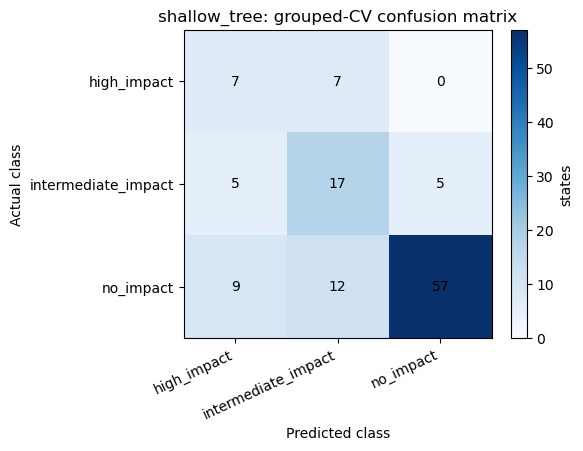

# RAPID collapse-impact classifier audit (rapid-impact-v1)

## Scope and frozen configuration

This is a real-network-only analysis of examples 02, 03, 05, 11, 21. It reads the existing RAPID and equivalent-resistance outputs and does not use `synthetic_runs/`. Validation is grouped leave-one-`example_id`-out, so a river example never appears in both sides of a fold.

The response metric `lag_to_inflow_peak_pct_shift_vs_base` is used only to create labels. Model inputs are the geometric / resistance-change features below.

| feature | description |
| --- | --- |
| len_fraction_width_weighted_log_lambda | Selected-domain length fraction * (-log10(Lambda_K)) * width_fraction |
| along_network_frac | Along-network fractional distance |

## Data audit

| Item | Count |
|---|---:|
| Assembled candidate rows | 171 |
| Examples assembled | 5 |
| Excluded: `boundary_relation != exact_match` | 25 |
| Excluded: missing primary x/y pair | 0 |
| Excluded by existing edge-compound filter | 31 |
| F

In [6]:
recommended = scores.iloc[0]['model']
matrix = confusion.loc[confusion.model.eq(recommended)].pivot(index='actual', columns='predicted', values='count')
fig, ax = plt.subplots(figsize=(5, 4))
image = ax.imshow(matrix, cmap='Blues')
ax.set(xticks=range(len(matrix.columns)), xticklabels=matrix.columns, yticks=range(len(matrix.index)), yticklabels=matrix.index, xlabel='Predicted class', ylabel='Actual class', title=f'{recommended}: grouped-CV confusion matrix')
for i in range(matrix.shape[0]):
    for j in range(matrix.shape[1]):
        ax.text(j, i, int(matrix.iloc[i, j]), ha='center', va='center')
fig.colorbar(image, ax=ax, label='states')
plt.xticks(rotation=25, ha='right')
plt.show()
print((RUN_DIR / 'REPORT.md').read_text())
